# Imports

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

# Functions & Utils

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

In [4]:
def train_one_epoch(model, train_loader, loss_fn, optimizer, epoch=None):

    model.train()

    loss_train = AverageMeter()

    with tqdm(train_loader, unit="batch") as tepoch:

        for noisy_images, clean_images in tepoch:

            if epoch is not None:
                tepoch.set_description(f"Epoch {epoch + 1}")

            noisy_images = noisy_images.to(device)
            clean_images = clean_images.to(device)

            optimizer.zero_grad()

            outputs = model(noisy_images)

            loss = loss_fn(outputs, clean_images)

            loss.backward()
            optimizer.step()

            loss_train.update(loss.item(), noisy_images.size(0))

            tepoch.set_postfix(loss=loss_train.avg)

    return model, loss_train.avg

In [5]:
def validation(model, valid_loader, loss_fn):

    model.eval()

    loss_valid = AverageMeter()

    with torch.no_grad():

        for noisy_images, clean_images in valid_loader:

            noisy_images = noisy_images.to(device)
            clean_images = clean_images.to(device)

            outputs = model(noisy_images)

            loss = loss_fn(outputs, clean_images)

            loss_valid.update(loss.item(), noisy_images.size(0))

    return loss_valid.avg

# Dataset

In [6]:
df = pd.read_excel("./datasets/Labels.xlsx")

noise_column = "Noise Type"
image_column = "Denoise Image"
noisy_column = "Noisy Image"

periodic_df = df[df[noise_column].astype(str).str.strip().str.lower() == "periodic"]

print("Number of periodic images:", len(periodic_df))


Number of periodic images: 450


In [7]:
image_pairs = []

for (filename, filename2) in zip(periodic_df[image_column], periodic_df[noisy_column]):

    noisy_path = os.path.join('./datasets/Dataset2/', str(filename2))
    clean_path = os.path.join('./datasets/Dataset2/', str(filename))

    if os.path.exists(noisy_path) and os.path.exists(clean_path):
        image_pairs.append((noisy_path, clean_path))

print("Number of paired images:", len(image_pairs))

Number of paired images: 450


In [8]:
class PeriodicNoiseDataset(Dataset):

    def __init__(self, image_pairs, image_size=256):
        self.image_pairs = image_pairs
        self.image_size = image_size

    def __len__(self):
        return len(self.image_pairs)

    def __getitem__(self, idx):

        noisy_path, clean_path = self.image_pairs[idx]

        noisy_image = Image.open(noisy_path).convert("L")
        clean_image = Image.open(clean_path).convert("L")

        noisy_image = noisy_image.resize((self.image_size, self.image_size))

        clean_image = clean_image.resize((self.image_size, self.image_size))

        noisy_image = np.array(noisy_image, dtype=np.float32) / 255.0

        clean_image = np.array(clean_image, dtype=np.float32) / 255.0

        noisy_image = torch.tensor(noisy_image).unsqueeze(0)
        clean_image = torch.tensor(clean_image).unsqueeze(0)

        return noisy_image, clean_image

In [9]:
train_pairs, test_pairs = train_test_split(image_pairs, test_size=0.15, random_state=0)

train_pairs, valid_pairs = train_test_split(train_pairs, test_size=0.1765, random_state=0)

train_dataset = PeriodicNoiseDataset(train_pairs)

valid_dataset = PeriodicNoiseDataset(valid_pairs)

test_dataset = PeriodicNoiseDataset(test_pairs)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

valid_loader = DataLoader(valid_dataset, batch_size=16, shuffle=False)

test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Testing images:", len(test_dataset))

Training images: 314
Validation images: 68
Testing images: 68


# Model

## Define Model

In [10]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super(ConvBlock, self).__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class PeriodicAutoencoder(nn.Module):

    def __init__(self):
        super(PeriodicAutoencoder, self).__init__()

        # Encoder
        self.encoder1 = ConvBlock(1, 64)
        self.encoder2 = ConvBlock(64, 128)
        self.encoder3 = ConvBlock(128, 256)
        self.encoder4 = ConvBlock(256, 512)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ConvBlock(512, 1024)

        # Decoder
        self.up4 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.decoder4 = ConvBlock(1024 + 512, 512)

        self.up3 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.decoder3 = ConvBlock(512 + 256, 256)

        self.up2 = nn.Upsample( scale_factor=2, mode="bilinear", align_corners=False)
        self.decoder2 = ConvBlock(256 + 128, 128)

        self.up1 = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.decoder1 = ConvBlock(128 + 64, 64)

        self.output = nn.Conv2d(64, 1, kernel_size=3, padding=1)

    def forward(self, x):

        # Encoder
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder
        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.decoder4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.decoder3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.decoder2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.decoder1(d1)

        output = torch.sigmoid(self.output(d1))

        return output

## Training

In [11]:
model = PeriodicAutoencoder().to(device)

In [13]:
loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [14]:
loss_train_hist = []
loss_valid_hist = []

best_loss_valid = torch.inf
epoch_counter = 0

In [15]:
num_epochs = 15

for epoch in range(num_epochs):

    model, loss_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch)

    loss_valid = validation(model, valid_loader, loss_fn)

    loss_train_hist.append(loss_train)
    loss_valid_hist.append(loss_valid)

    if loss_valid < best_loss_valid:

        torch.save(model.state_dict(), "./models/Periodic Autoencoder.pt")

        best_loss_valid = loss_valid

    print(f"Train: Loss = {loss_train:.6f}")
    print(f"Valid: Loss = {loss_valid:.6f}")
    print()

    epoch_counter += 1

Epoch 1: 100%|██████████| 20/20 [00:16<00:00,  1.19batch/s, loss=0.0186]


Train: Loss = 0.018580
Valid: Loss = 0.081932



Epoch 2: 100%|██████████| 20/20 [00:15<00:00,  1.30batch/s, loss=0.00828]


Train: Loss = 0.008280
Valid: Loss = 0.041080



Epoch 3: 100%|██████████| 20/20 [00:15<00:00,  1.30batch/s, loss=0.00613]


Train: Loss = 0.006128
Valid: Loss = 0.010831



... (20 outputs left out)

Epoch 14: 100%|██████████| 20/20 [00:15<00:00,  1.26batch/s, loss=0.00214]


Train: Loss = 0.002141
Valid: Loss = 0.002375



Epoch 15: 100%|██████████| 20/20 [00:15<00:00,  1.29batch/s, loss=0.0022] 


Train: Loss = 0.002203
Valid: Loss = 0.002784



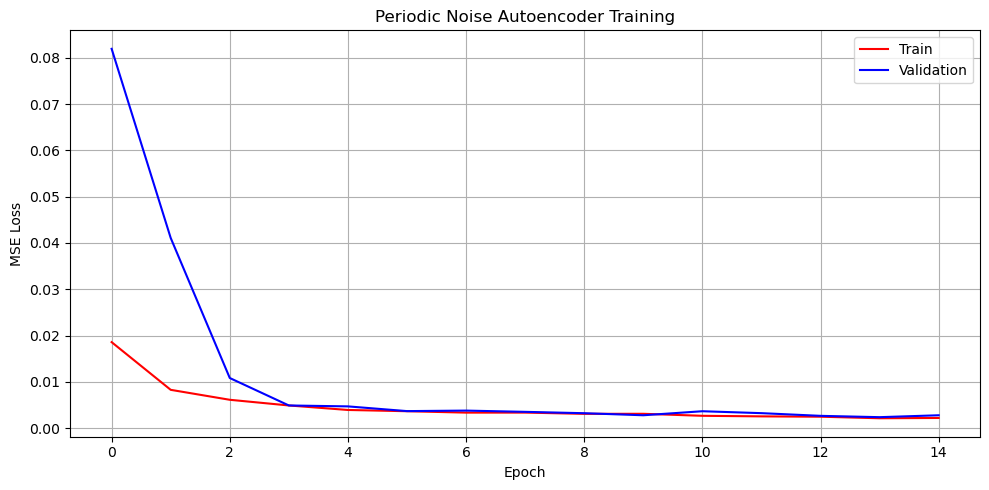

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(range(epoch_counter), loss_train_hist, 'r-', label='Train')
plt.plot(range(epoch_counter), loss_valid_hist, 'b-', label='Validation')

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Periodic Noise Autoencoder Training")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.plot(range(epoch_counter), loss_train_hist, 'r-', label='Train')
plt.plot(range(epoch_counter), loss_valid_hist, 'b-', label='Validation')

plt.xlabel('Epoch')
plt.ylabel('loss')
plt.grid(True)
plt.legend()

## Evaluation

In [17]:
model.load_state_dict(torch.load("./models/Periodic Autoencoder.pt", map_location=device))

model.to(device)
model.eval()

PeriodicAutoencoder(
  (encoder1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (encoder2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (encoder3): ConvBlock(
    (block): Sequential(
      (0): Co

In [18]:
model.eval()

loss_test = AverageMeter()

with torch.no_grad():

    for noisy_images, clean_images in test_loader:

        noisy_images = noisy_images.to(device)
        clean_images = clean_images.to(device)

        outputs = model(noisy_images)

        loss = loss_fn(outputs, clean_images)

        loss_test.update(loss.item(), noisy_images.size(0))

print(f"Test MSE Loss: {loss_test.avg:.6f}")

Test MSE Loss: 0.002451


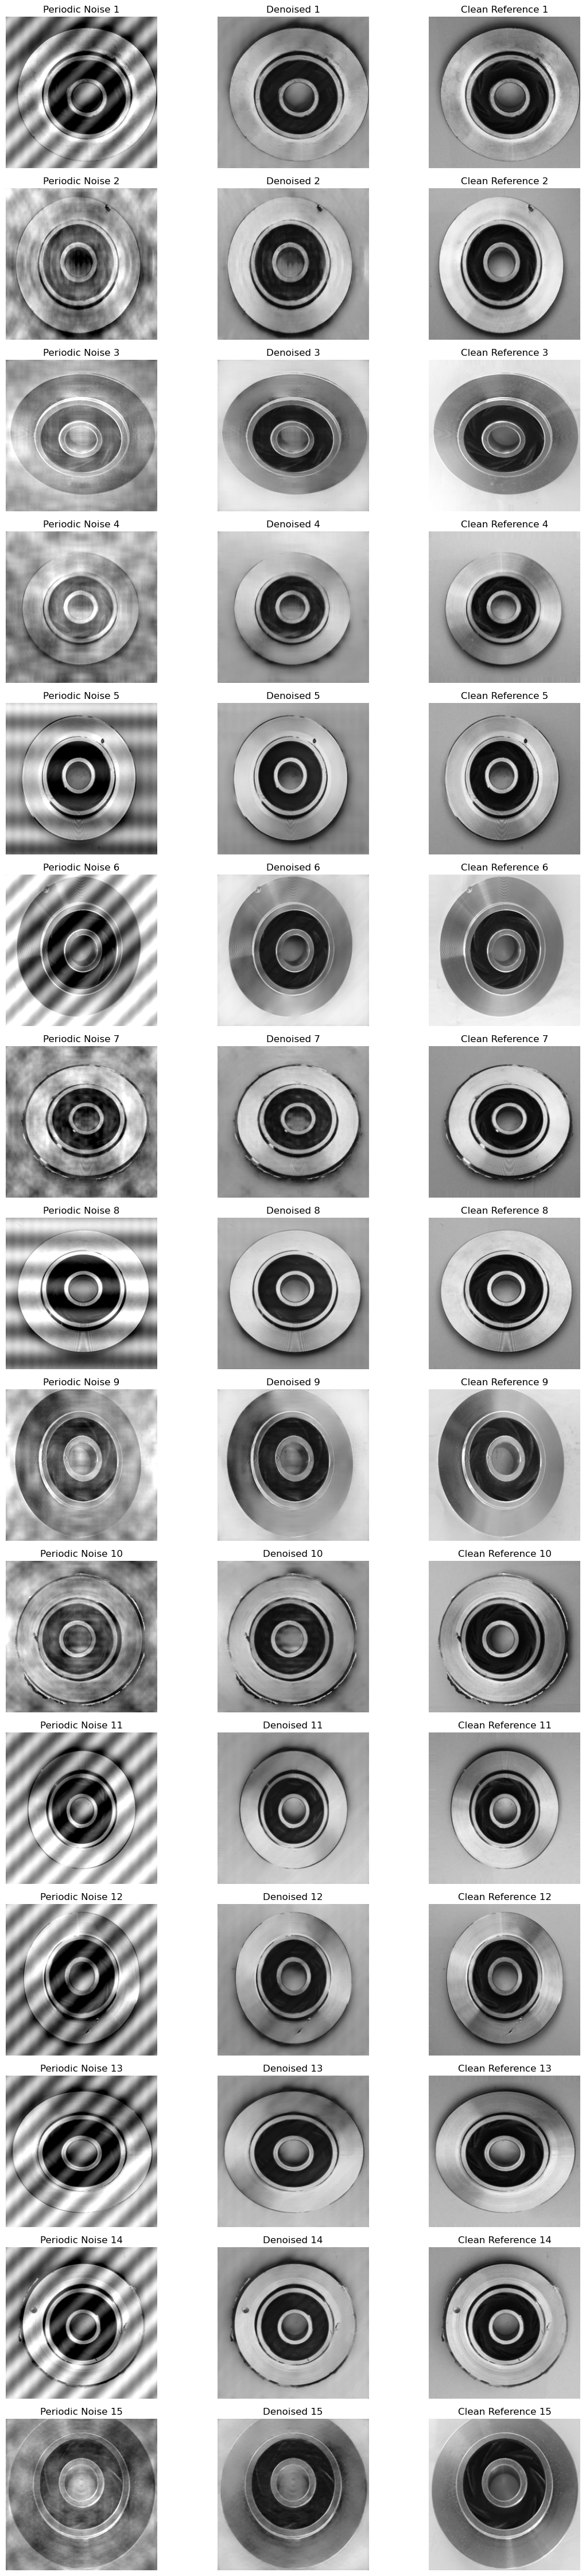

In [19]:
model.eval()

num_examples = 15
shown = 0

plt.figure(figsize=(12, num_examples * 3))

with torch.no_grad():

    for noisy_images, clean_images in test_loader:

        noisy_images = noisy_images.to(device)
        clean_images = clean_images.to(device)

        outputs = model(noisy_images)

        for i in range(noisy_images.size(0)):

            noisy_image = noisy_images[i].cpu().squeeze().numpy()
            clean_image = clean_images[i].cpu().squeeze().numpy()
            denoised_image = outputs[i].cpu().squeeze().numpy()

            plt.subplot(num_examples, 3, shown * 3 + 1)
            plt.imshow(noisy_image, cmap="gray", vmin=0, vmax=1)
            plt.title(f"Periodic Noise {shown + 1}")
            plt.axis("off")

            plt.subplot(num_examples, 3, shown * 3 + 2)
            plt.imshow(denoised_image, cmap="gray", vmin=0, vmax=1)
            plt.title(f"Denoised {shown + 1}")
            plt.axis("off")

            plt.subplot(num_examples, 3, shown * 3 + 3)
            plt.imshow(clean_image, cmap="gray", vmin=0, vmax=1)
            plt.title(f"Clean Reference {shown + 1}")
            plt.axis("off")

            shown += 1

            if shown >= num_examples:
                break

        if shown >= num_examples:
            break

plt.tight_layout()
plt.show()